# 4G Network Congestion Classification

**Goal:** look at the data of a 4G tower and predict *which type of congestion* it has.

| Answer | Meaning |
|---|---|
| NC | No congestion |
| 4G_RAN_CONGESTION | Radio part of the 4G tower is overloaded |
| 4G_BACKHAUL_CONGESTION | Link from the 4G tower to the core network is overloaded |
| 3G_BACKHAUL_CONGESTION | Same problem on the 3G link |

**Steps:** load data -> look at data -> clean -> train two models -> compare -> check mistakes -> find important inputs -> predict test file.

## 1. Load the data

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

ROOT = Path.cwd()
if not (ROOT / "data").exists() and (ROOT.parent / "data").exists():
    ROOT = ROOT.parent

train = pd.read_csv(ROOT / "data" / "train_upd.csv")   # has the correct answers
test = pd.read_csv(ROOT / "data" / "test_upd.csv")     # no answers - we must predict
print("Train rows:", len(train), "| Test rows:", len(test))
train.head()

Train rows: 78560 | Test rows: 26305


,cell_name,4G_rat,par_year,par_month,par_day,par_hour,par_min,subscriber_count,web_browsing_total_bytes,video_total_bytes,...,email_total_bytes,weather_total_bytes,media_total_bytes,mms_total_bytes,others_total_bytes,beam_direction,cell_range,tilt,ran_vendor,Congestion_Type
0,1090595862,1,2018,12,15,0,50,152,315,59012,...,10,33,46,39,103,69,6,2,ERICSSON,4G_BACKHAUL_CONGESTION
1,4826375369,1,2018,12,7,20,5,54,1871,334,...,22,20,7,10,21,93,7,5,NOKIA,NC
2,3607540856,1,2018,12,5,16,35,277,887,945,...,14,91,49,147,159,77,6,3,ERICSSON,3G_BACKHAUL_CONGESTION
3,1245076813,0,2018,12,16,21,60,51,8577,494,...,10,63,42,75,35,95,7,2,HUAWEI,3G_BACKHAUL_CONGESTION
4,404129745,1,2018,12,4,6,60,117,2084,1056,...,67,59,91,197,316,112,3,5,HUAWEI,4G_RAN_CONGESTION


## 2. Check the data and the answers (target)

Missing values: 0
Congestion_Type
NC                        19771
4G_BACKHAUL_CONGESTION    19765
3G_BACKHAUL_CONGESTION    19688
4G_RAN_CONGESTION         19336
Name: count, dtype: int64


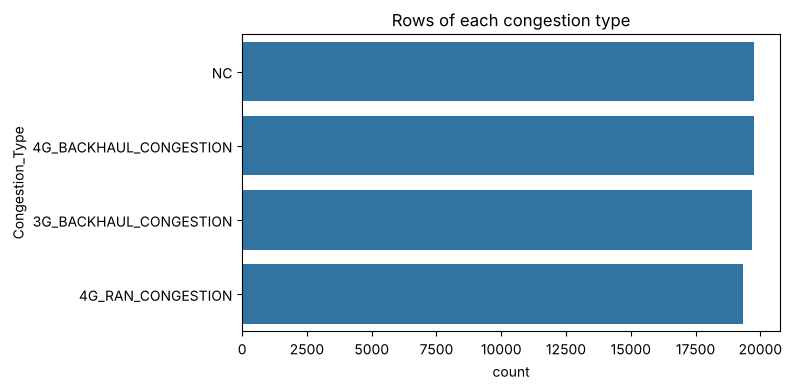

In [2]:
TARGET = "Congestion_Type"
IDENTIFIER = "cell_name"
print("Missing values:", int(train.isna().sum().sum()))
print(train[TARGET].value_counts())

plt.figure(figsize=(8, 4))
sns.countplot(data=train, y=TARGET, order=train[TARGET].value_counts().index)
plt.title("Rows of each congestion type")
plt.tight_layout()
plt.show()

**What we see:** no missing values, and all 4 types have almost the same number of rows (balanced), so *accuracy* is a fair score.

## 3. Look at vendors and traffic

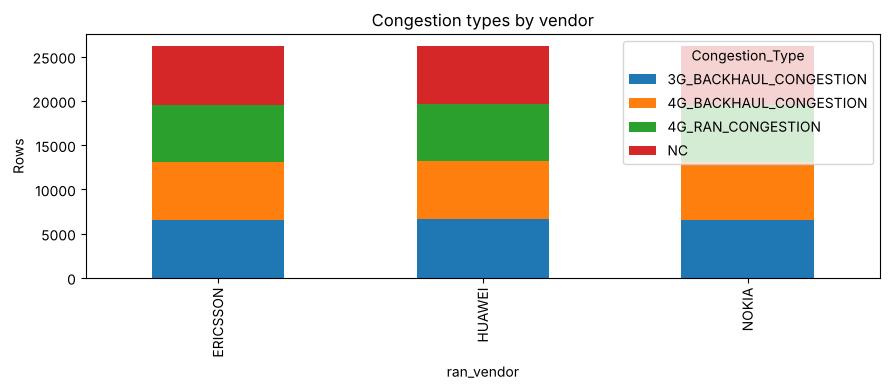

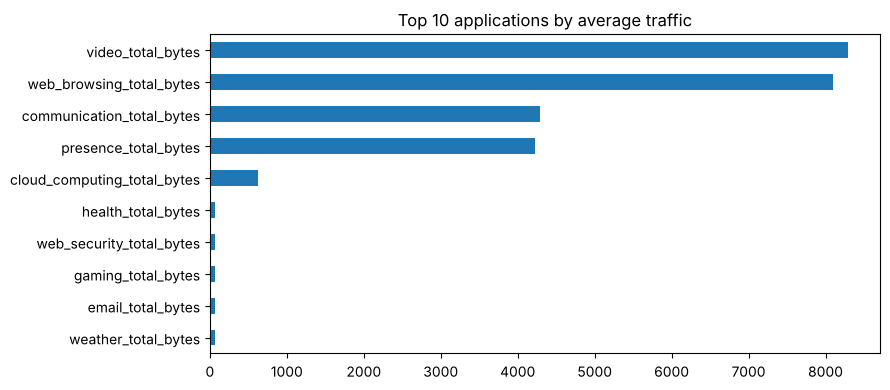

In [3]:
pd.crosstab(train["ran_vendor"], train[TARGET]).plot(kind="bar", stacked=True, figsize=(9, 4))
plt.title("Congestion types by vendor")
plt.ylabel("Rows")
plt.tight_layout()
plt.show()

traffic_cols = [c for c in train.columns if c.endswith("_total_bytes")]
train[traffic_cols].mean().sort_values().tail(10).plot(kind="barh", figsize=(9, 4))
plt.title("Top 10 applications by average traffic")
plt.tight_layout()
plt.show()

**What we see:** every vendor has all 4 congestion types in equal amounts, so the vendor alone does not tell us the answer.

## 4. Prepare the data

* `cell_name` is just an ID (different in every row) - not used for learning.
* `par_year`, `par_month`, `4G_rat` are the same in every row - they give no information, so we remove them.
* The vendor name is text, so we turn it into numbers (one-hot encoding).

In [4]:
USELESS = ["par_year", "par_month", "4G_rat"]
y = train[TARGET].astype(str)
X = train.drop(columns=[TARGET, IDENTIFIER] + USELESS)
X_test = test.drop(columns=[IDENTIFIER] + USELESS).reindex(columns=X.columns)

def make_pipeline(model):
    text_cols = X.select_dtypes(exclude="number").columns.tolist()
    prep = ColumnTransformer([("vendor", OneHotEncoder(handle_unknown="ignore"), text_cols)],
                             remainder="passthrough")
    return Pipeline([("prep", prep), ("model", model)])

print("Input columns used:", X.shape[1])

Input columns used: 34


## 5. Train two models and compare

* **Random Forest** - many decision trees that vote.
* **Gradient Boosting** - trees built one after another, each fixing the mistakes of the one before.

We hide 25% of the data to test the model, and we also use **5-fold cross-validation** (testing 5 times on different parts) for a more trustworthy score.

,Test accuracy,5-fold CV
Random Forest,0.7441,0.7430
Gradient Boosting,0.7970,0.7932


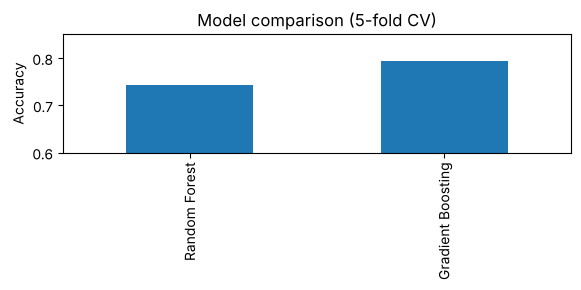

Best model: Gradient Boosting


In [5]:
models = {
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=18, min_samples_leaf=2,
                                            n_jobs=-1, random_state=42),
    "Gradient Boosting": HistGradientBoostingClassifier(max_iter=300, random_state=42),
}
X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

results = {}
for name, model in models.items():
    pipe = make_pipeline(model).fit(X_train, y_train)
    acc = accuracy_score(y_valid, pipe.predict(X_valid))
    cv = cross_val_score(make_pipeline(model), X, y, cv=5, n_jobs=-1).mean()
    results[name] = (acc, cv, pipe)

scores = pd.DataFrame({n: {"Test accuracy": a, "5-fold CV": c} for n, (a, c, _) in results.items()}).T
display(scores.round(4))
scores["5-fold CV"].plot(kind="bar", ylim=(0.6, 0.85), figsize=(6, 3), title="Model comparison (5-fold CV)")
plt.ylabel("Accuracy")
plt.tight_layout()
plt.show()

best_name = scores["5-fold CV"].idxmax()
best_pipe = results[best_name][2]
print("Best model:", best_name)

## 6. Where does the model make mistakes? (confusion matrix)

                        precision    recall  f1-score   support

3G_BACKHAUL_CONGESTION       0.77      0.79      0.78      4922
4G_BACKHAUL_CONGESTION       0.70      0.70      0.70      4941
     4G_RAN_CONGESTION       0.83      0.79      0.81      4834
                    NC       0.89      0.90      0.90      4943

              accuracy                           0.80     19640
             macro avg       0.80      0.80      0.80     19640
          weighted avg       0.80      0.80      0.80     19640



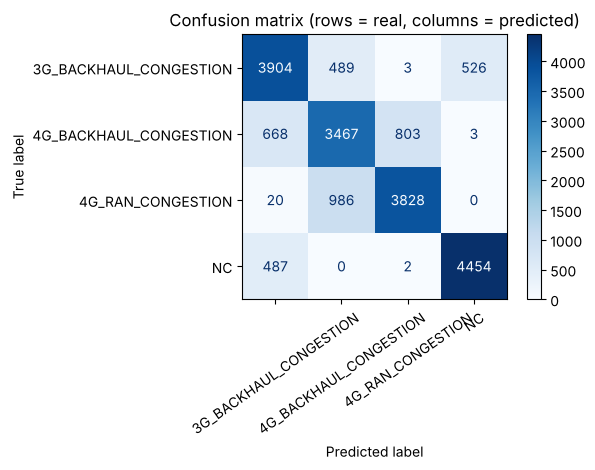

In [6]:
pred = best_pipe.predict(X_valid)
print(classification_report(y_valid, pred))
labels = sorted(y.unique())
ConfusionMatrixDisplay(confusion_matrix(y_valid, pred, labels=labels), display_labels=labels).plot(
    xticks_rotation=35, cmap="Blues", values_format="d")
plt.title("Confusion matrix (rows = real, columns = predicted)")
plt.tight_layout()
plt.show()

**How to read it:** the diagonal is correct answers. `NC` is easiest. The model mixes up **4G backhaul** and **4G RAN** the most - this is where it can still improve.

## 7. Which inputs matter most?

We shuffle one column at a time and see how much the accuracy drops. A bigger drop means that column matters more.

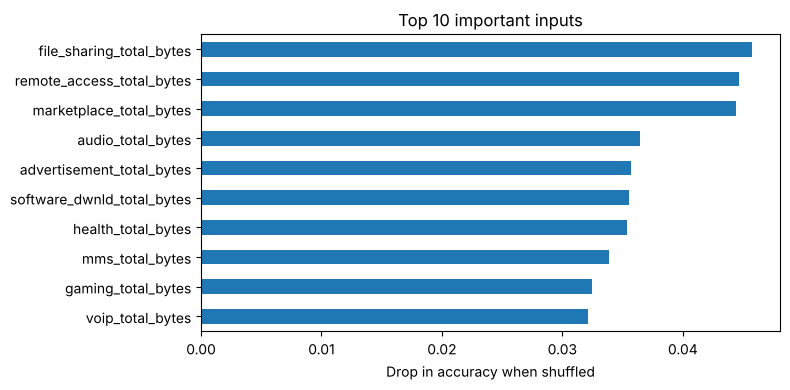

In [7]:
sample = X_valid.sample(3000, random_state=42)
imp = permutation_importance(best_pipe, sample, y_valid.loc[sample.index], n_repeats=3, random_state=42, n_jobs=-1)
importance = pd.Series(imp.importances_mean, index=X.columns).sort_values(ascending=False)
importance.head(10).sort_values().plot(kind="barh", figsize=(8, 4), title="Top 10 important inputs")
plt.xlabel("Drop in accuracy when shuffled")
plt.tight_layout()
plt.show()

**What we see:** many application-traffic columns matter about equally; the model uses the overall traffic mix, not one single column.

## 8. Predict the test file and save

In [8]:
final = make_pipeline(models[best_name]).fit(X, y)     # train on ALL labelled rows
out = pd.DataFrame({IDENTIFIER: test[IDENTIFIER], TARGET: final.predict(X_test)})
(ROOT / "outputs").mkdir(exist_ok=True)
out.to_csv(ROOT / "outputs" / "congestion_predictions.csv", index=False)
joblib.dump(final, ROOT / "outputs" / "model.joblib")
print("Saved", len(out), "predictions")
out.head()

Saved 26305 predictions


,cell_name,Congestion_Type
0,4398447675,3G_BACKHAUL_CONGESTION
1,4152570378,3G_BACKHAUL_CONGESTION
2,2902602672,4G_RAN_CONGESTION
3,1080083695,NC
4,4413045057,4G_BACKHAUL_CONGESTION


## 9. Conclusion

* We built a model that predicts the congestion type of a 4G cell from its traffic, subscriber and tower data.
* **Gradient Boosting (about 79%)** performed better than **Random Forest (about 74%)**.
* The model is best at spotting `NC` and weakest at separating 4G backhaul from 4G RAN congestion.
* **Future work:** tune model settings, and look for extra data that separates the two 4G types better.